# Data Engineering & Monetization Analytics in Mobile Games
**Author:** Kanat Mukhammedkanafiya, student at University of London (Data Science and Business Analytics)

**Goal:** build a small end-to-end pipeline for in-app purchase (IAP) data of a free-to-play mobile game and measure retention and lifetime value (LTV).

**Stack:** Python (pandas, NumPy), SQLite, SQL (CTEs, recursive CTEs, window functions), Matplotlib.

**Pipeline:**
1. **Data synthesis.** Generate raw event logs (`user_id`, `timestamp`, `event_type`, `item_id`, `revenue`) for three player segments.
2. **ETL.** Clean the raw logs with pandas, normalize them into `users` and `events`, and load them into SQLite.
3. **Analytics (SQL).** Calculate retention, cumulative ARPU (LTV) by day of life, ARPU, ARPPU and payer conversion.

> **Note:** the data is synthetic. Segment shares and spending behaviour are assumptions built into the generator, so the results show that the pipeline and metrics work. They are not findings about real players.

In [1]:
import sqlite3
import warnings
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")  # hide pandas FutureWarnings to keep output readable
DB_PATH = "game_analytics.db"

## 1. Data synthesis
Each user belongs to one segment: **90% F2P**, **8% Dolphins** (moderate spenders) and **2% Whales** (heavy spenders). The segment controls how many days a user stays active and how likely they are to buy something in a session.

About 1% of timestamps are set to `NaN` on purpose, to imitate broken records in raw logs.

In [2]:
def generate_game_logs(num_users=5000, days=30, seed=42):
    rng = np.random.default_rng(seed)
    start_date = datetime(2026, 9, 1)
    end_date = start_date + timedelta(days=days)

    users = pd.DataFrame({
        "user_id": range(1, num_users + 1),
        "segment": rng.choice(["f2p", "dolphin", "whale"], p=[0.90, 0.08, 0.02], size=num_users),
    })

    items = {"starter_pack": 1.99, "battle_pass": 9.99, "gem_chest": 49.99, "legendary_chest": 99.99}
    events = []

    for row in users.itertuples():
        uid = row.user_id
        install_date = start_date + timedelta(days=int(rng.integers(0, days)), minutes=int(rng.integers(0, 1440)))
        events.append([uid, install_date, "install", None, 0.0])

        # Number of active days depends on the segment
        if row.segment == "whale":
            active_days = int(rng.integers(10, days))
        elif row.segment == "dolphin":
            active_days = int(rng.integers(3, 15))
        else:
            active_days = int(rng.integers(1, 7))

        for i in range(active_days):
            session_time = install_date + timedelta(days=i, minutes=int(rng.integers(10, 600)))
            if session_time > end_date:
                break
            events.append([uid, session_time, "session_start", None, 0.0])

            # Purchase probability depends on the segment
            if row.segment == "dolphin" and rng.random() < 0.15:
                item = rng.choice(["starter_pack", "battle_pass"])
                events.append([uid, session_time + timedelta(minutes=5), "purchase", item, items[item]])
            elif row.segment == "whale" and rng.random() < 0.40:
                item = rng.choice(["battle_pass", "gem_chest", "legendary_chest"], p=[0.2, 0.5, 0.3])
                events.append([uid, session_time + timedelta(minutes=10), "purchase", item, items[item]])

    df = pd.DataFrame(events, columns=["user_id", "timestamp", "event_type", "item_id", "revenue"])

    # Corrupt ~1% of timestamps to simulate dirty raw data
    corrupt_idx = rng.choice(df.index, size=int(len(df) * 0.01), replace=False)
    df.loc[corrupt_idx, "timestamp"] = pd.NaT

    return df.sort_values("timestamp").reset_index(drop=True), users


raw_df, segments_df = generate_game_logs(num_users=2000)
print(f"Raw events: {len(raw_df):,}")
print(segments_df["segment"].value_counts().to_string())
raw_df.head()

Raw events: 9,951
segment
f2p        1791
dolphin     162
whale        47


,user_id,timestamp,event_type,item_id,revenue
0,690,2026-09-01 00:16:00,install,NaN,0.0
1,1036,2026-09-01 00:18:00,install,NaN,0.0
2,657,2026-09-01 00:22:00,install,NaN,0.0
3,690,2026-09-01 00:37:00,session_start,NaN,0.0
4,1524,2026-09-01 01:32:00,install,NaN,0.0


## 2. ETL: clean, normalize, load into SQLite

In [3]:
# Clean: drop rows without a timestamp, fill missing values
clean_df = raw_df.dropna(subset=["timestamp"]).copy()
clean_df["revenue"] = clean_df["revenue"].fillna(0.0)
clean_df["item_id"] = clean_df["item_id"].fillna("none")

print(f"Rows before cleaning: {len(raw_df):,}")
print(f"Rows after cleaning:  {len(clean_df):,} ({len(raw_df) - len(clean_df)} dropped)")

# Normalize: a user's cohort date is the first time we saw them
users_df = (clean_df.groupby("user_id", as_index=False)["timestamp"].min()
            .rename(columns={"timestamp": "first_seen_at"}))
events_df = clean_df[["user_id", "timestamp", "event_type", "item_id", "revenue"]].copy()

# SQLite stores datetimes as text
users_df["first_seen_at"] = users_df["first_seen_at"].dt.strftime("%Y-%m-%d %H:%M:%S")
events_df["timestamp"] = events_df["timestamp"].dt.strftime("%Y-%m-%d %H:%M:%S")

print(f"Users: {len(users_df):,} | Events: {len(events_df):,}")

Rows before cleaning: 9,951
Rows after cleaning:  9,852 (99 dropped)
Users: 2,000 | Events: 9,852


In [4]:
schema = """
DROP TABLE IF EXISTS events;
DROP TABLE IF EXISTS users;

CREATE TABLE users (
    user_id       INTEGER PRIMARY KEY,
    first_seen_at TIMESTAMP NOT NULL
);

CREATE TABLE events (
    event_id        INTEGER PRIMARY KEY AUTOINCREMENT,
    user_id         INTEGER NOT NULL REFERENCES users(user_id) ON DELETE CASCADE,
    event_timestamp TIMESTAMP NOT NULL,
    event_type      TEXT NOT NULL,
    item_id         TEXT,
    revenue         REAL NOT NULL
);

CREATE INDEX idx_events_user_id   ON events(user_id);
CREATE INDEX idx_events_timestamp ON events(event_timestamp);
"""

# Tables are recreated on every run, so re-running the notebook never duplicates data
with sqlite3.connect(DB_PATH) as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(schema)
    conn.executemany("INSERT INTO users (user_id, first_seen_at) VALUES (?, ?)",
                     users_df.itertuples(index=False, name=None))
    conn.executemany(
        "INSERT INTO events (user_id, event_timestamp, event_type, item_id, revenue) VALUES (?, ?, ?, ?, ?)",
        events_df.itertuples(index=False, name=None),
    )
    n_users = conn.execute("SELECT COUNT(*) FROM users").fetchone()[0]
    n_events = conn.execute("SELECT COUNT(*) FROM events").fetchone()[0]

print(f"Loaded into {DB_PATH}: {n_users:,} users, {n_events:,} events")

Loaded into game_analytics.db: 2,000 users, 9,852 events


## 3. Retention and cumulative LTV by day of life

**How it is calculated:**
- **Mature cohort only.** A user is included only if they installed at least 14 days before the end of the data. Users who installed late cannot have a day 14 yet, and including them would push LTV down.
- **Fixed denominator.** Revenue for each day of life is summed over *all* cohort users and divided by cohort size. Then a running total is taken. Users who churned still count with the money they already paid, so the curve can never go down.
- A recursive CTE produces every day from 0 to 14, so days without revenue still appear in the result.

In [5]:
ltv_query = """
WITH RECURSIVE
params AS (
    SELECT DATE(MAX(event_timestamp)) AS obs_end FROM events
),
cohort AS (                      -- users observed for at least 14 full days
    SELECT u.user_id, DATE(u.first_seen_at) AS install_date
    FROM users u, params p
    WHERE DATE(u.first_seen_at) <= DATE(p.obs_end, '-14 days')
),
days(lifetime_day) AS (          -- day 0 .. day 14
    SELECT 0 UNION ALL SELECT lifetime_day + 1 FROM days WHERE lifetime_day < 14
),
daily AS (
    SELECT
        CAST(JULIANDAY(DATE(e.event_timestamp)) - JULIANDAY(c.install_date) AS INTEGER) AS lifetime_day,
        COUNT(DISTINCT e.user_id) AS active_users,
        SUM(e.revenue)            AS revenue
    FROM cohort c
    JOIN events e ON e.user_id = c.user_id
    GROUP BY lifetime_day
)
SELECT
    d.lifetime_day,
    COALESCE(dl.active_users, 0) AS active_users,
    ROUND(100.0 * COALESCE(dl.active_users, 0) / (SELECT COUNT(*) FROM cohort), 1) AS retention_pct,
    ROUND(SUM(COALESCE(dl.revenue, 0)) OVER (ORDER BY d.lifetime_day
          ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
          / (SELECT COUNT(*) FROM cohort), 2) AS cumulative_arpu
FROM days d
LEFT JOIN daily dl ON dl.lifetime_day = d.lifetime_day
ORDER BY d.lifetime_day;
"""

with sqlite3.connect(DB_PATH) as conn:
    ltv_df = pd.read_sql(ltv_query, conn)
    cohort_size = conn.execute("""
        SELECT COUNT(*) FROM users
        WHERE DATE(first_seen_at) <= DATE((SELECT MAX(event_timestamp) FROM events), '-14 days')
    """).fetchone()[0]

print(f"Mature cohort size: {cohort_size:,} users")
ltv_df

Mature cohort size: 1,099 users


,lifetime_day,active_users,retention_pct,cumulative_arpu
0,0,1099,100.0,0.35
1,1,908,82.6,1.14
2,2,770,70.1,1.84
3,3,577,52.5,2.47
4,4,425,38.7,3.10
5,5,240,21.8,3.35
6,6,108,9.8,3.93
7,7,69,6.3,4.48
8,8,65,5.9,4.98
9,9,59,5.4,5.45


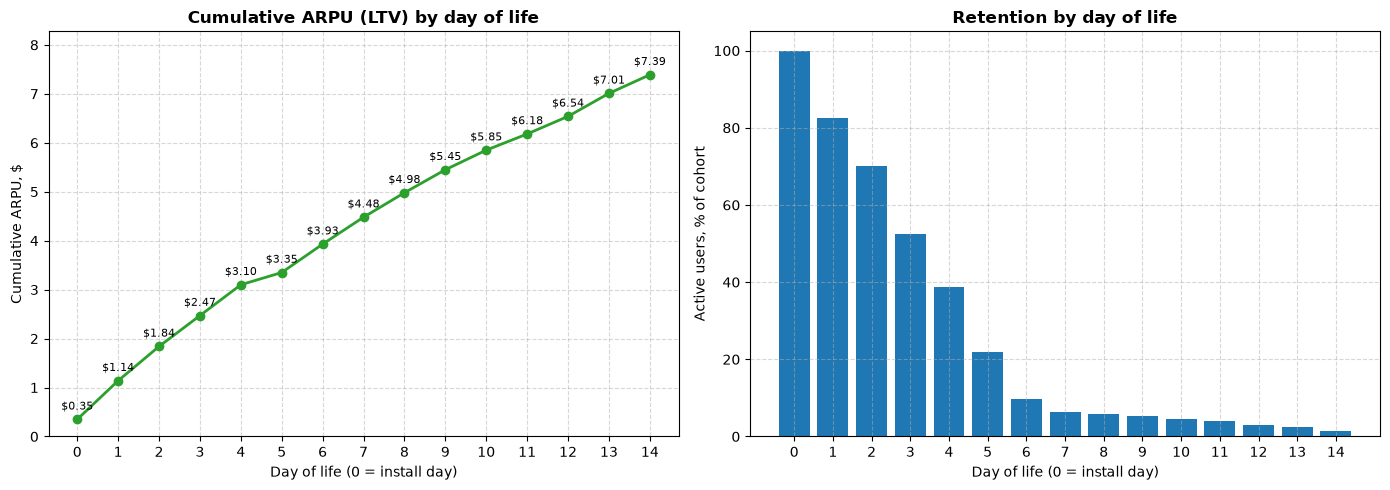

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(ltv_df["lifetime_day"], ltv_df["cumulative_arpu"], marker="o", color="#2ca02c", linewidth=2)
for x, y in zip(ltv_df["lifetime_day"], ltv_df["cumulative_arpu"]):
    ax1.annotate(f"${y:.2f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax1.set_title("Cumulative ARPU (LTV) by day of life", fontweight="bold")
ax1.set_xlabel("Day of life (0 = install day)")
ax1.set_ylabel("Cumulative ARPU, $")
ax1.set_ylim(0, ltv_df["cumulative_arpu"].max() * 1.12)

ax2.bar(ltv_df["lifetime_day"], ltv_df["retention_pct"], color="#1f77b4")
ax2.set_title("Retention by day of life", fontweight="bold")
ax2.set_xlabel("Day of life (0 = install day)")
ax2.set_ylabel("Active users, % of cohort")

for ax in (ax1, ax2):
    ax.set_xticks(range(0, 15))
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("ltv_chart.png", dpi=150)
plt.show()

## 4. Monetization summary (whole period, all users)

In [7]:
summary_query = """
WITH per_user AS (
    SELECT u.user_id, COALESCE(SUM(e.revenue), 0) AS revenue
    FROM users u
    LEFT JOIN events e ON e.user_id = u.user_id AND e.event_type = 'purchase'
    GROUP BY u.user_id
)
SELECT
    COUNT(*)                                                    AS users,
    SUM(revenue > 0)                                            AS payers,
    ROUND(100.0 * SUM(revenue > 0) / COUNT(*), 2)               AS payer_conversion_pct,
    ROUND(SUM(revenue), 2)                                      AS total_revenue,
    ROUND(SUM(revenue) / COUNT(*), 2)                           AS arpu,
    ROUND(SUM(revenue) / NULLIF(SUM(revenue > 0), 0), 2)        AS arppu
FROM per_user;
"""

items_query = """
SELECT item_id,
       COUNT(*)                                                       AS purchases,
       ROUND(SUM(revenue), 2)                                         AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1)     AS revenue_share_pct
FROM events
WHERE event_type = 'purchase'
GROUP BY item_id
ORDER BY revenue DESC;
"""

with sqlite3.connect(DB_PATH) as conn:
    summary_df = pd.read_sql(summary_query, conn)
    items_df = pd.read_sql(items_query, conn)

display(summary_df)
display(items_df)

,users,payers,payer_conversion_pct,total_revenue,arpu,arppu
0,2000,140,7.0,15481.89,7.74,110.58


,item_id,purchases,revenue,revenue_share_pct
0,legendary_chest,84,8399.16,54.3
1,gem_chest,113,5648.87,36.5
2,battle_pass,126,1258.74,8.1
3,starter_pack,88,175.12,1.1


## 5. Conclusions and limitations
- **LTV** grows steadily over the first two weeks: most revenue comes from a small group of paying users who keep playing.
- **Retention** drops sharply after day 0–1, which is typical for F2P games. The F2P segment, 90% of users, leaves within a week.
- **Revenue concentration:** a small share of payers produces almost all revenue, and expensive items (`gem_chest`, `legendary_chest`) bring most of the money.

**Limitations.** The data is synthetic, so these patterns come from the generator's assumptions (segment shares, purchase probabilities). On real data the same pipeline and SQL would work unchanged; only the generation step would be replaced by loading real logs.